# 3. BW + PLI + EM + MA (Sec. IV-B, Figs. 9, 10, 11) and the paper's claims

PEAF / SEAF (EMD + LMS) vs PDAF / SDAF (LMS only), `scripts/04_four_noises.py`.
Plots: "X ours" solid, "X paper" dashed.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import FIGURES_DIR, RESULTS_DIR
pd.set_option("display.precision", 2)

## Fig. 9: example

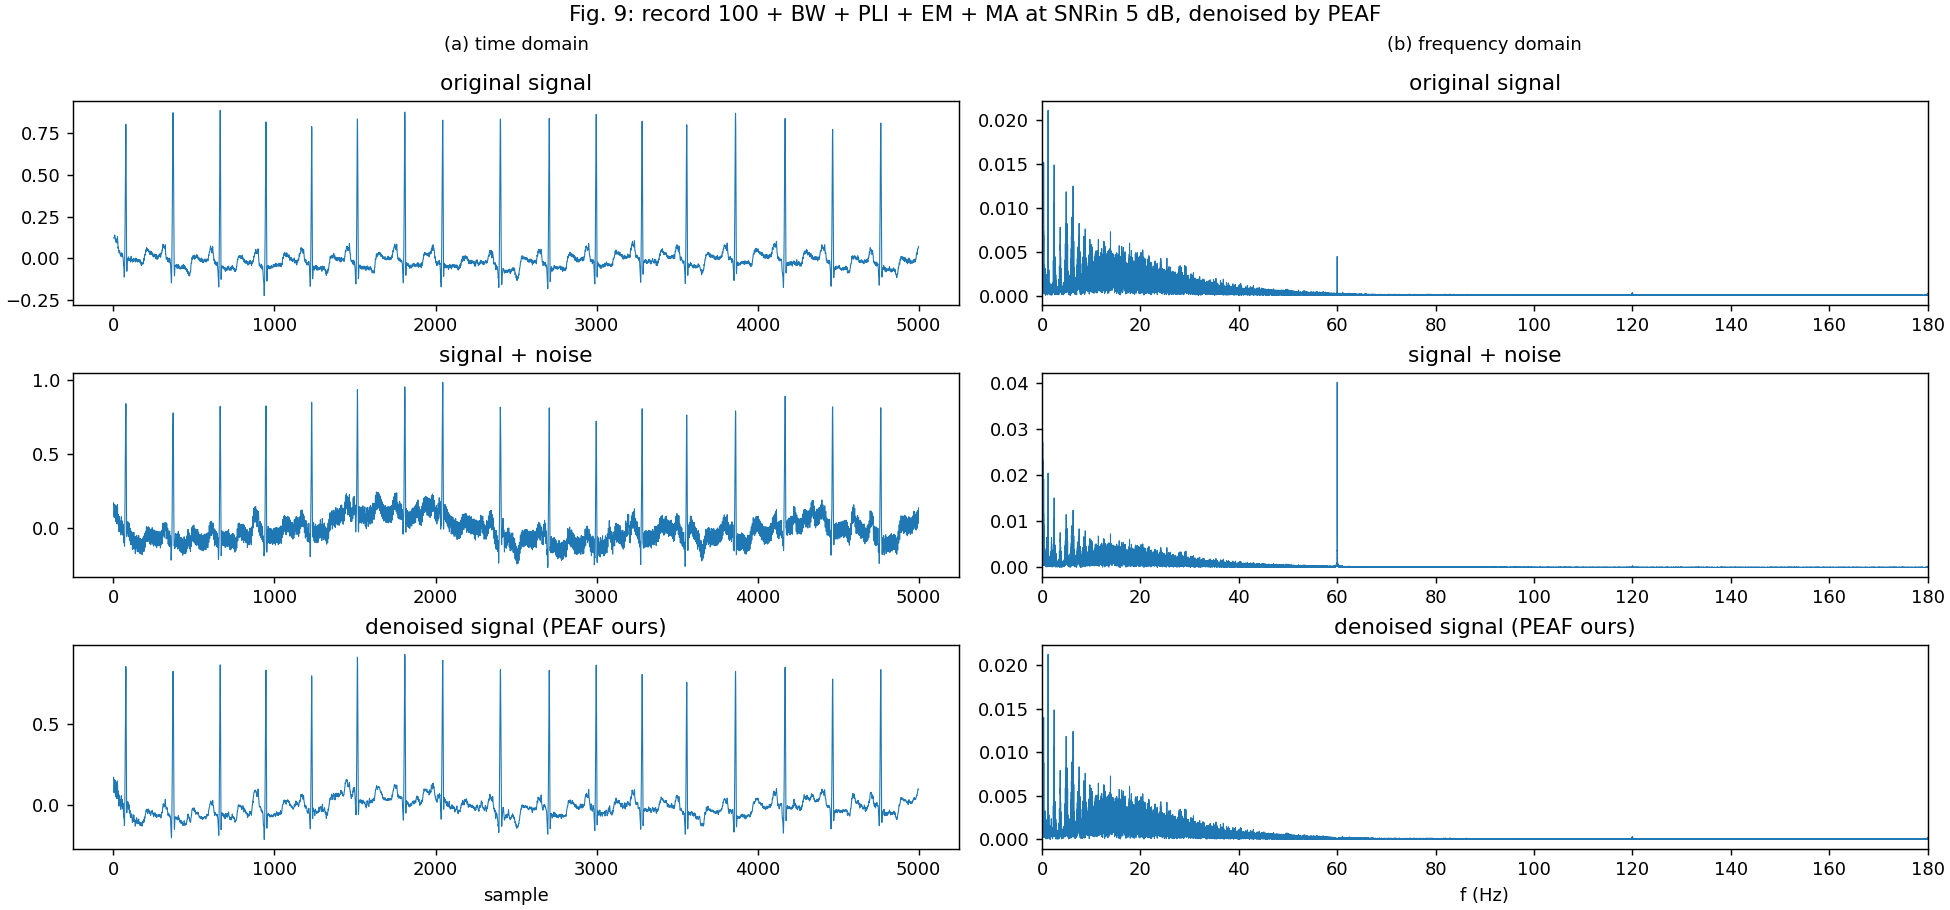

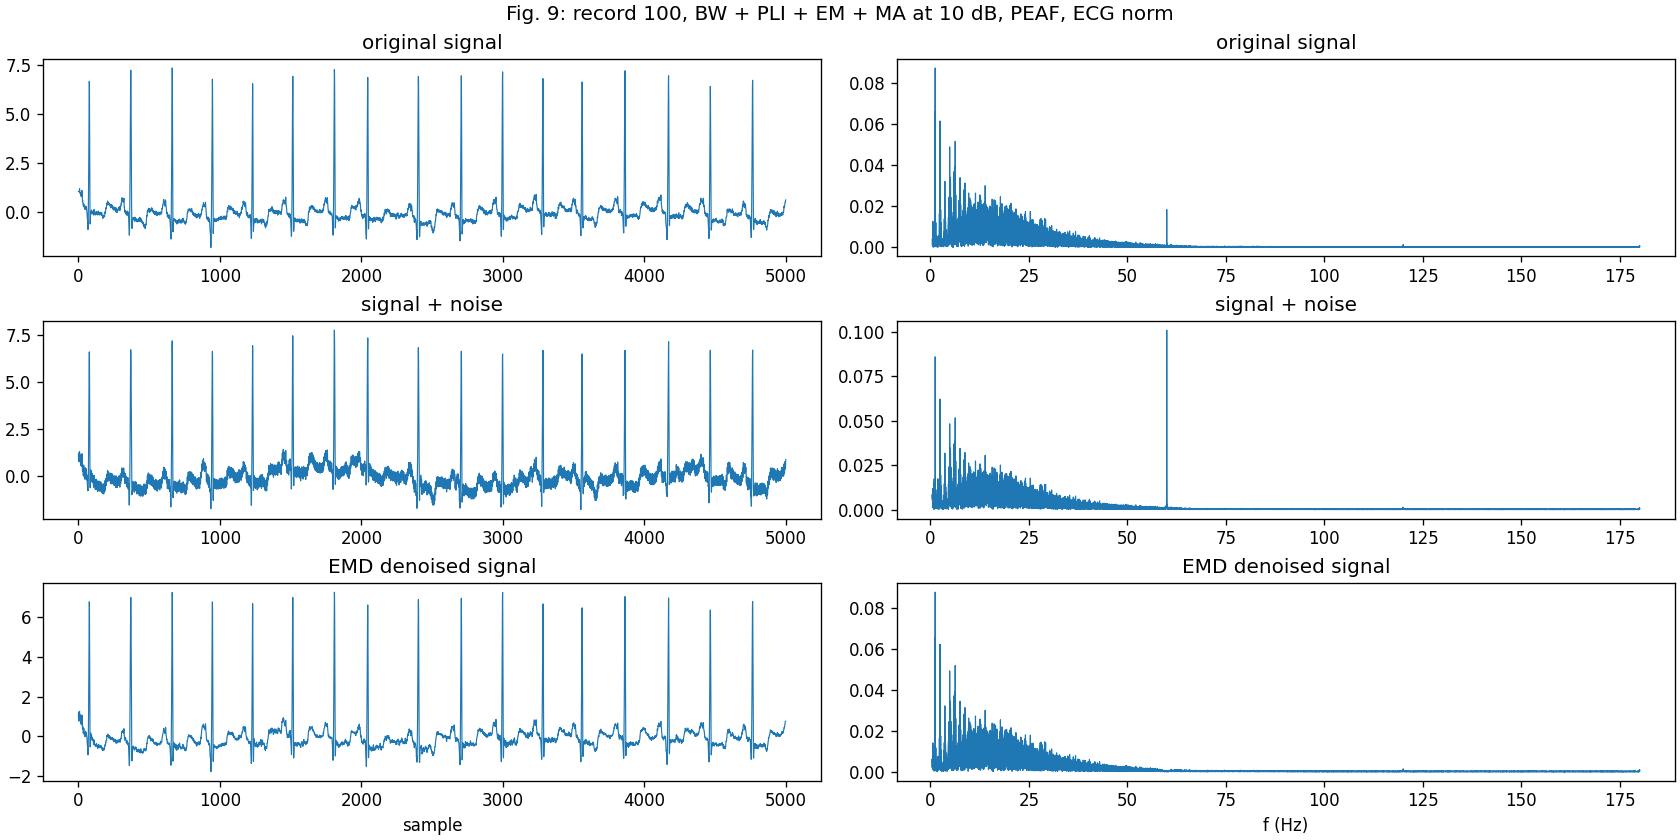

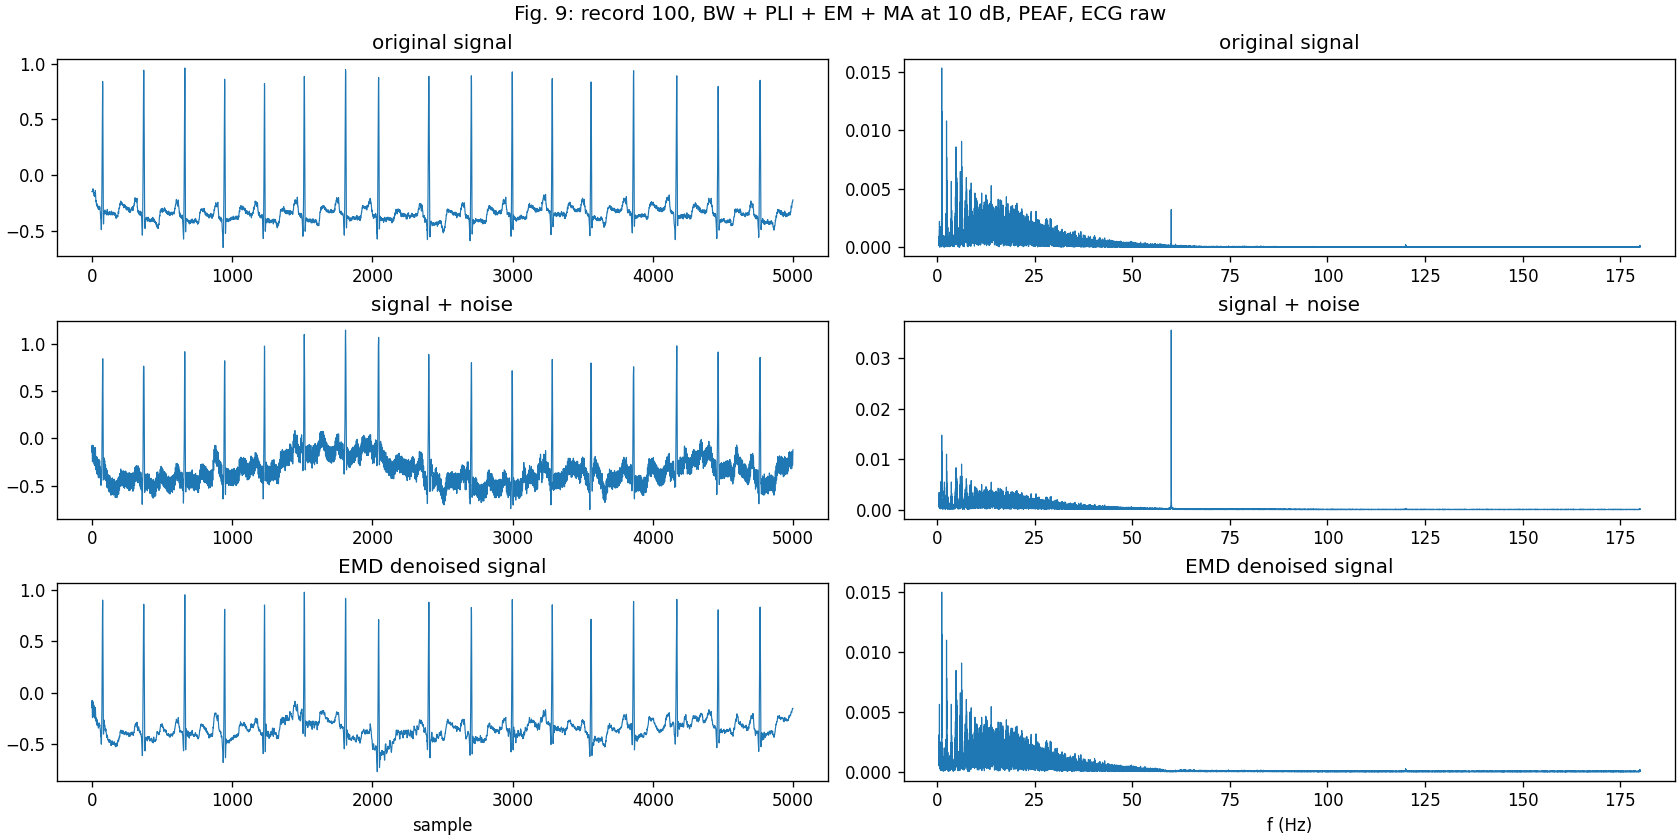

In [2]:
display(*[Image(p, width=1000) for p in sorted(FIGURES_DIR.glob("fig9_*.png"))])

## Fig. 10: SNRimp per record
The paper's text says SNRin = 10 dB, but its values match its Fig. 11 at -5 dB, so ours is shown at both.

In [3]:
four = pd.read_csv(RESULTS_DIR / "four_noises.csv")
methods = ["PEAF", "SEAF", "PDAF", "SDAF"]
for s in (-5, 10):
    t = four[four.SNRin_dB == s].pivot(index="record", columns="method", values="SNRimp_dB")[methods]
    t["best"] = t.idxmax(axis=1)
    display(Markdown(f"**ours, SNRin = {s} dB**"), t)

**ours, SNRin = -5 dB**

method,PEAF,SEAF,PDAF,SDAF,best
record,,,,,
100,12.96,13.66,15.97,13.77,PDAF
103,13.23,14.05,16.26,14.09,PDAF
104,12.61,13.24,14.91,13.51,PDAF
105,12.99,13.81,16.18,13.99,PDAF
106,12.88,13.83,15.65,13.94,PDAF
111,10.82,12.27,13.32,12.19,PDAF
113,11.64,12.30,13.62,12.43,PDAF
115,11.92,12.47,14.00,12.63,PDAF
116,13.03,13.60,15.95,13.61,PDAF


**ours, SNRin = 10 dB**

method,PEAF,SEAF,PDAF,SDAF,best
record,,,,,
100,9.01,9.42,9.60,9.57,PDAF
103,10.36,10.99,12.01,11.27,PDAF
104,7.10,7.27,5.40,7.56,SDAF
105,10.21,11.03,10.34,11.58,SDAF
106,8.52,9.44,7.80,9.58,SDAF
111,0.90,2.21,1.15,2.30,SDAF
113,2.80,3.16,1.84,3.35,SDAF
115,2.84,2.98,2.67,3.03,SDAF
116,9.40,9.46,9.74,9.85,SDAF


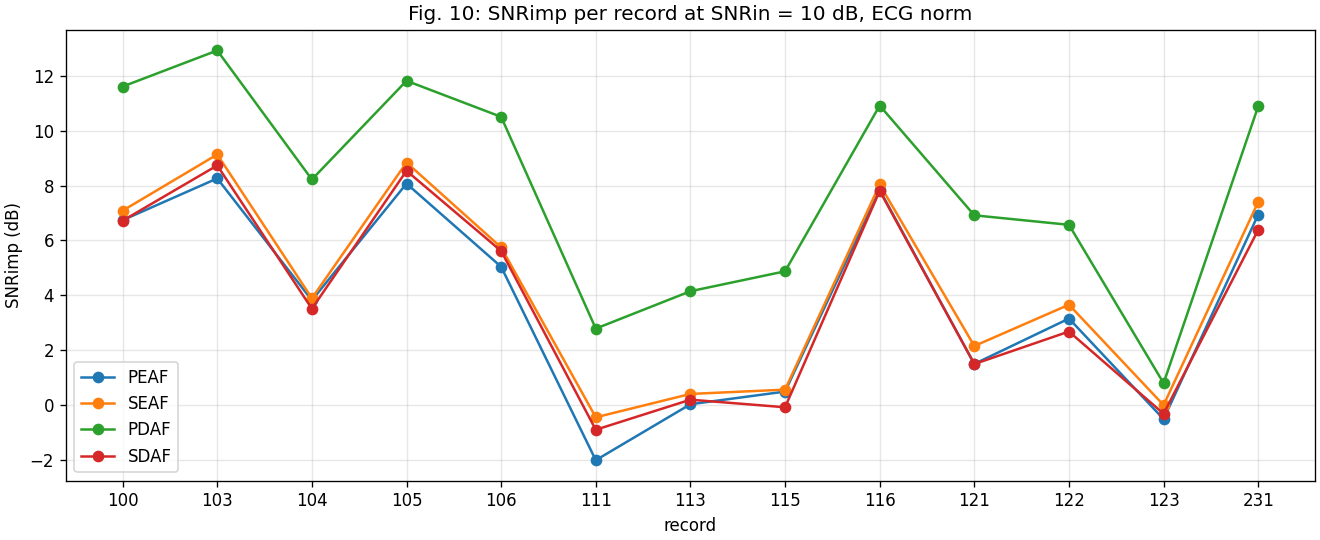

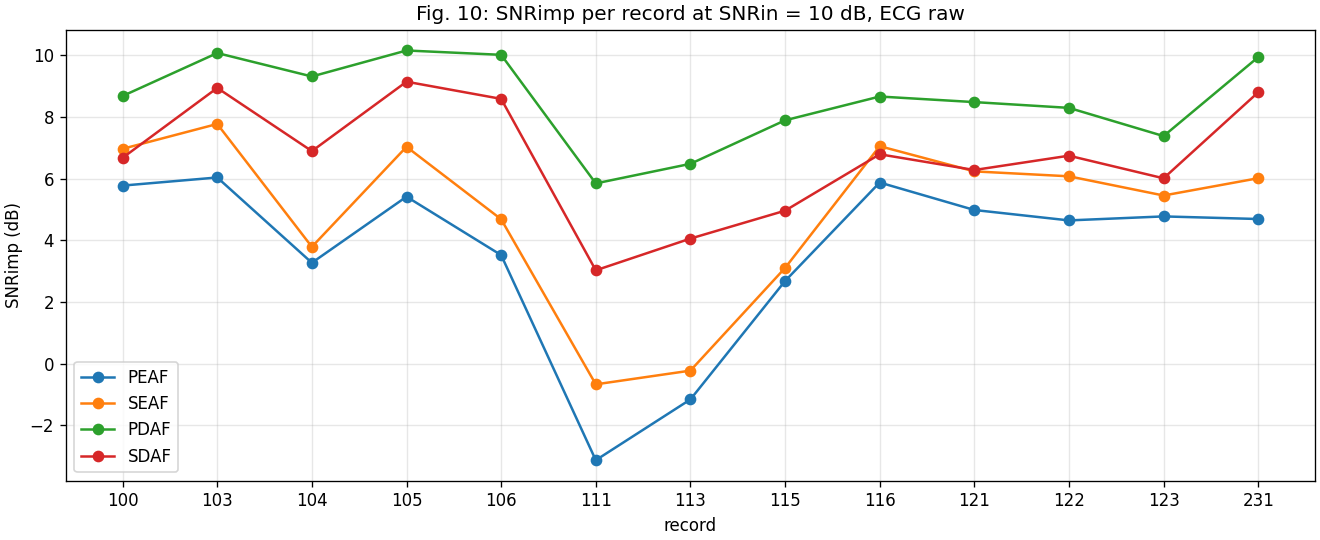

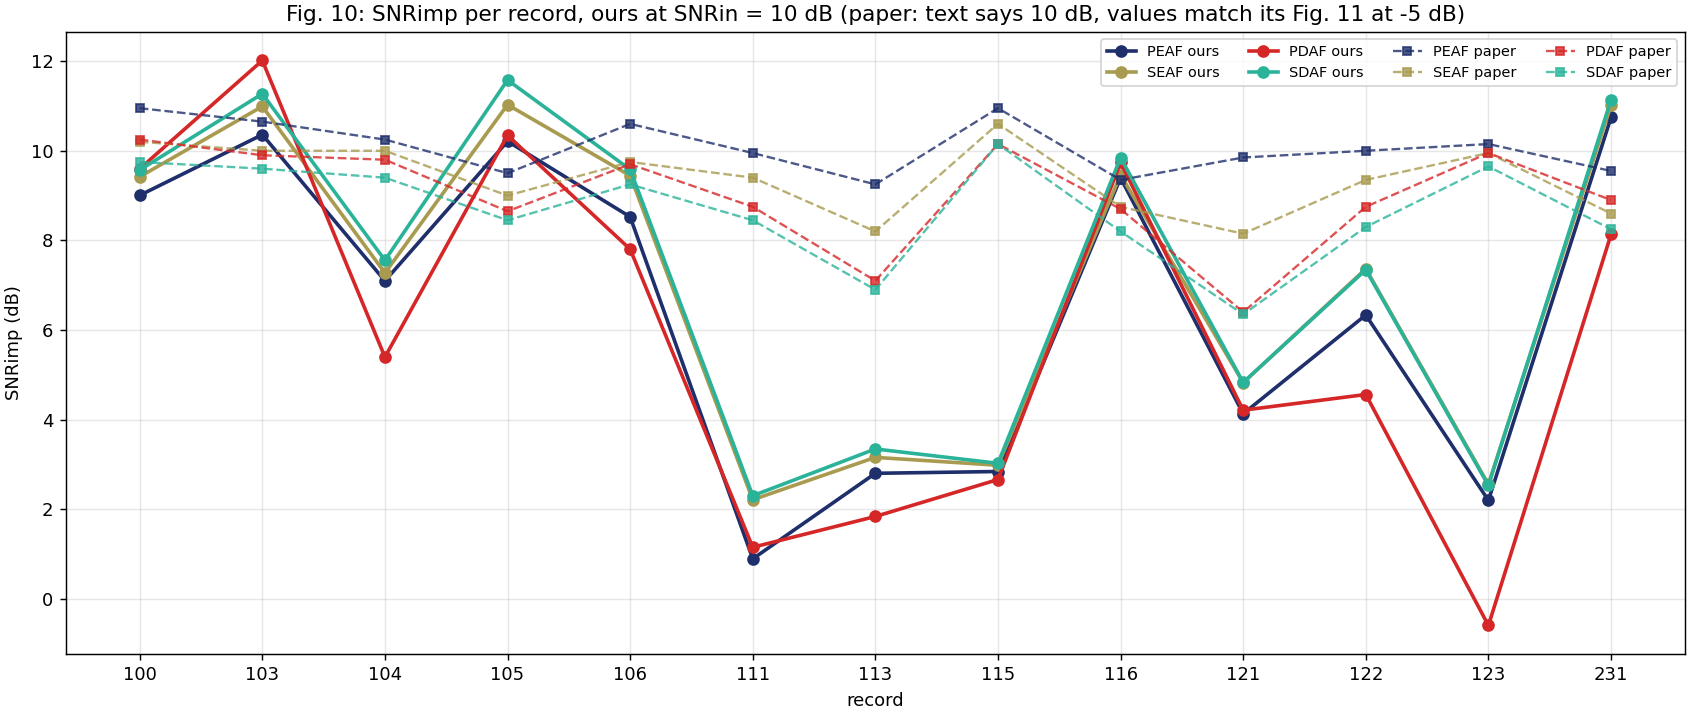

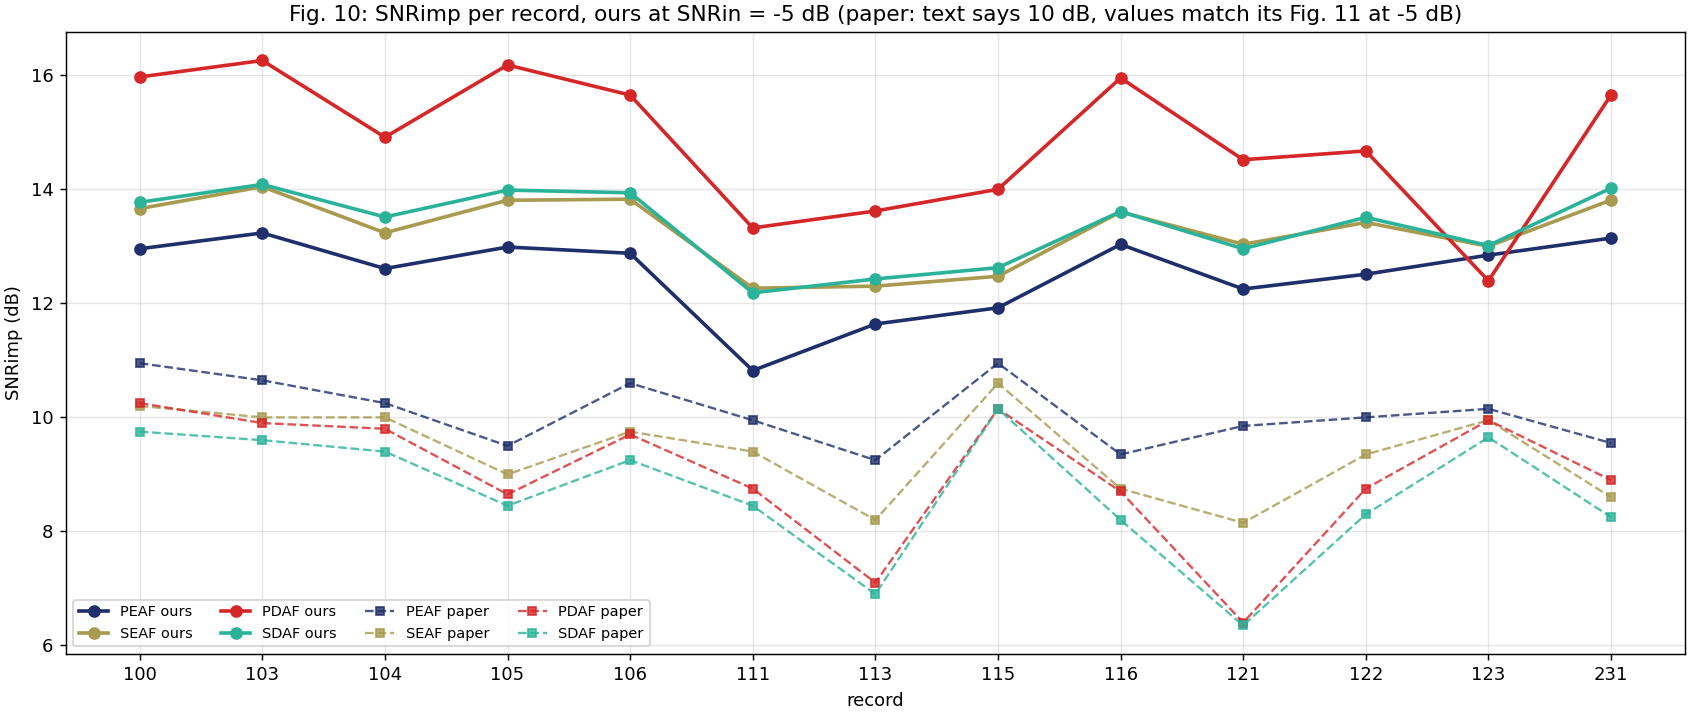

In [4]:
display(*[Image(p, width=1000) for p in sorted(FIGURES_DIR.glob("fig10_*.png"))])

## Fig. 11: SNRimp vs SNRin (mean over the 13 records)

In [5]:
from src import paper_values as paper
ours = four.groupby(["method", "SNRin_dB"]).SNRimp_dB.mean().unstack().loc[methods]
theirs = pd.DataFrame(paper.FIG11_SNR_IMP, index=paper.FIG11_SNRS).T.loc[methods]
pd.concat({"ours": ours, "paper": theirs}, axis=1)

ours                                   paper                    \
SNRin_dB    -5     -2      0      3     6     10    -5    -2     0     3    
PEAF      12.53  12.04  11.52  10.46  9.10  6.50  10.35  9.55  9.35  7.15   
SEAF      13.27  12.77  12.22  11.12  9.72  7.06  10.40  9.10  8.80  6.80   
PDAF      14.86  13.85  12.96  11.27  9.19  5.91  10.25  9.20  8.70  6.60   
SDAF      13.36  12.83  12.32  11.26  9.80  7.23  10.25  8.75  8.15  6.15   

                      
SNRin_dB    6     10  
PEAF      5.55  4.30  
SEAF      5.30  4.10  
PDAF      4.75  3.45  
SDAF      4.50  3.40

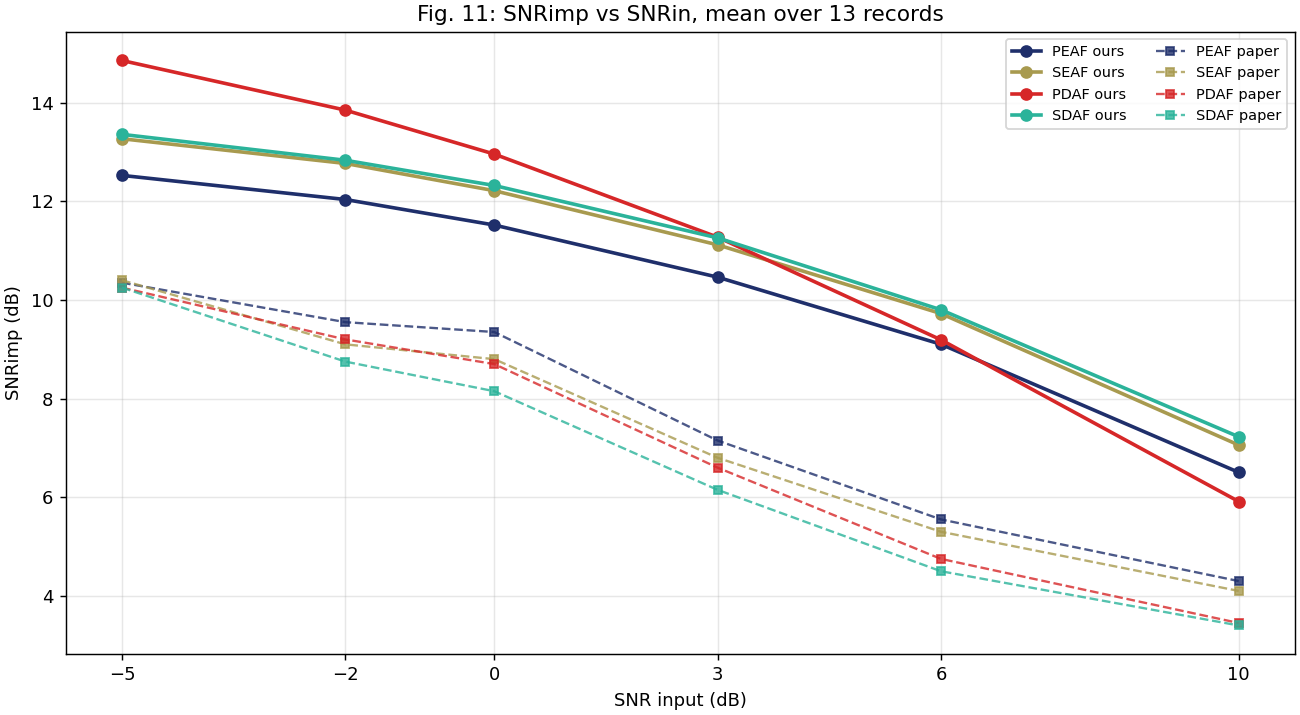

In [6]:
display(Image(FIGURES_DIR / "fig11_snr_imp_vs_snr_in_four_methods.png", width=900))

## Claims of the paper

In [7]:
text = (RESULTS_DIR / "comparison_with_paper.md").read_text(encoding="utf-8")
display(Markdown(text[text.index("## Claims of the paper"):]))

## Claims of the paper

| claim | ours | reproduced |
|---|---|---|
| Sec. III-A: IMF1 is the best input for PLI | best: IMF1 28.98 dB; paper's IMF1 28.98 dB | Yes |
| Sec. III-A: IMF5~8 is the best input for BW | best: no EMD 14.22 dB; paper's IMF5~8 13.88 dB | Partly |
| Sec. III-A: IMF3~8 is the best input for EM | best: IMF1~8 13.69 dB; paper's IMF3~8 13.45 dB | Partly |
| Sec. III-A: no EMD is the best input for MA | best: no EMD 13.47 dB; paper's no EMD 13.47 dB | Yes |
| Fig. 7: LMS is better and more stable than NLMS and RLS | LMS has the best SNRout at 0/5 SNRin (winners: EMD+RLS, EMD+RLS, EMD+RLS, EMD+RLS, EMD+RLS) | No |
| Fig. 8: EMD + LMS beats articles [28, 21, 22] (their values as reported) | ours better than the best article on 2/5 records | Partly |
| Fig. 8: our EMD + LMS SNR output matches the paper's | mean difference -3.72 dB, mean |difference| 3.78 dB | Partly |
| Fig. 10 (SNRin -5 dB): PEAF is best on every record | PEAF best on 0/13 records; mean SNRimp PEAF 12.53, SEAF 13.27, PDAF 14.86, SDAF 13.36 | No |
| Fig. 10 (SNRin 10 dB): PEAF is best on every record | PEAF best on 0/13 records; mean SNRimp PEAF 6.50, SEAF 7.06, PDAF 5.91, SDAF 7.23 | No |
| Fig. 11: PEAF is best at every SNRin | PEAF best at 0/6 SNRin (winners: PDAF, PDAF, PDAF, PDAF, SDAF, SDAF) | No |
| Figs. 10-11: EMD + adaptive filter beats adaptive filter only | best EMD method (PEAF/SEAF) beats best direct method (PDAF/SDAF) at 0/6 SNRin | No |
| Fig. 11: SNRimp falls as SNRin rises | true for 4/4 methods (PEAF, SEAF, PDAF, SDAF) | Yes |
| Fig. 11: our PEAF SNRimp matches the paper's | mean difference +2.65 dB, mean |difference| 2.65 dB | Partly |
